In [1]:
import configparser
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
os.chdir('../')

In [2]:
dataset = 'all_noHypoHyper'

In [3]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('../data.ini')
data = data['DEFAULT']

## Load

In [4]:
mutpanning = pd.read_csv("../" + data[f'mutpanning___{dataset}___out_dir'] + '/SignificanceFiltered/Significancecolorectal.txt', sep='\t', engine='python', comment='#')
mutpanning_RAS = pd.read_csv("../" + data[f'mutpanning___{dataset}_RAS___out_dir'] + '/SignificanceFiltered/Significancecolorectal.txt', sep='\t', engine='python', comment='#')
mutpanning_nonRAS = pd.read_csv("../" + data[f'mutpanning___{dataset}_nonRAS___out_dir'] + '/SignificanceFiltered/Significancecolorectal.txt', sep='\t', engine='python', comment='#')

In [5]:
mutpanning[mutpanning['Significance'] == 0]

,Name,TargetSize,TargetSizeSyn,Count,CountSyn,Significance,FDR
0,APC,12582.226860,3971.410942,722,13,0.0,0.0
1,TP53,3206.497181,1306.629807,583,8,0.0,0.0
2,KRAS,861.661011,309.431417,414,10,0.0,0.0
3,PIK3CA,4539.954571,1286.958130,307,2,0.0,0.0
4,FAT4,25962.553816,11168.937707,243,77,0.0,0.0
5,LRP1B,20226.379778,8373.497069,183,49,0.0,0.0
6,BRAF,3651.077707,1173.301037,178,3,0.0,0.0
7,FBXW7,3967.040415,1357.015804,172,4,0.0,0.0
8,AMER1,5986.610199,1893.954548,84,6,0.0,0.0
9,ARID1A,11992.575627,5104.440300,78,17,0.0,0.0


## Significance analysis

In [6]:
pv_qfreq = 0.01

In [7]:
# create dataframes containing p values and the number of genes with p-value lower than that
numGenes_pvLower = pd.DataFrame(
    [(i, len(mutpanning.loc[mutpanning['Significance'] <= i, 'Name'])) for i in np.clip(np.arange(pv_qfreq, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['significance', 'numGenes']
)
numGenes_pvLower_RAS = pd.DataFrame(
    [(i, len(mutpanning_RAS.loc[mutpanning_RAS['Significance'] <= i, 'Name'])) for i in np.clip(np.arange(pv_qfreq, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['significance', 'numGenes']
)
numGenes_pvLower_nonRAS = pd.DataFrame(
    [(i, len(mutpanning_nonRAS.loc[mutpanning_nonRAS['Significance'] <= i, 'Name'])) for i in np.clip(np.arange(pv_qfreq, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['significance', 'numGenes']
)

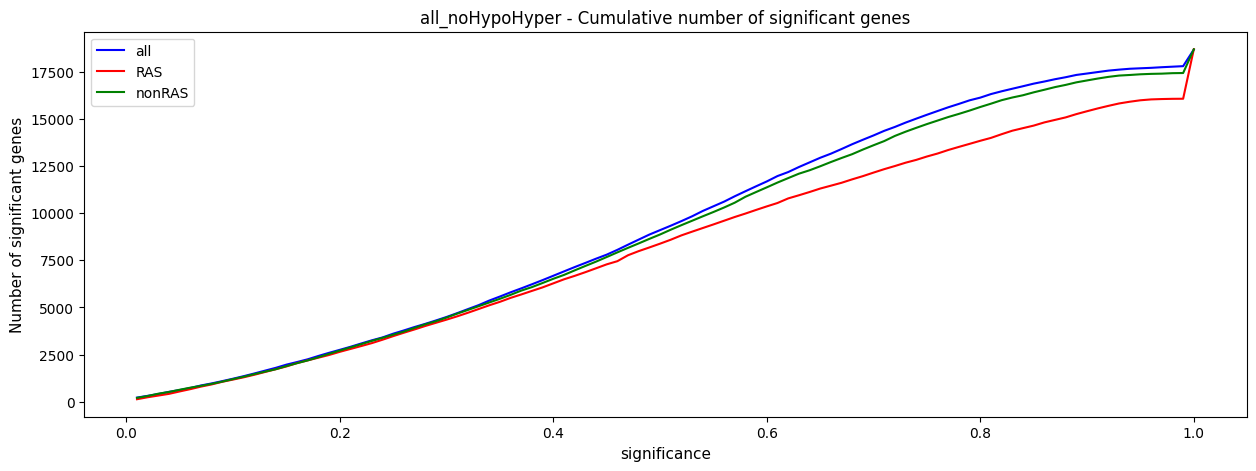

In [8]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - Cumulative number of significant genes')
plt.plot(numGenes_pvLower.set_index('significance'), label='all', color='blue')
plt.plot(numGenes_pvLower_RAS.set_index('significance'), label='RAS', color='red')
plt.plot(numGenes_pvLower_nonRAS.set_index('significance'), label='nonRAS', color='green')
plt.xlabel('significance', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig("../" + data[f'plots___{dataset}'] + dataset + '_mutpanning_cumulativeNumSignificantGenes.png')
plt.show()

In [9]:
numGenes_pvLower.head(10)

,significance,numGenes
0,0.01,220
1,0.02,312
2,0.03,409
3,0.04,524
4,0.05,619
5,0.06,727
6,0.07,863
7,0.08,971
8,0.09,1094
9,0.10,1221


In [10]:
genes_all_pv01 = mutpanning.loc[mutpanning['Significance'] < 0.1, 'Name']
genes_all_pv005 = mutpanning.loc[mutpanning['Significance'] < 0.05, 'Name']

genes_RAS_pv01 = mutpanning_RAS.loc[mutpanning_RAS['Significance'] < 0.1, 'Name']
genes_RAS_pv005 = mutpanning_RAS.loc[mutpanning_RAS['Significance'] < 0.05, 'Name']

genes_nonRAS_pv01 = mutpanning_nonRAS.loc[mutpanning_nonRAS['Significance'] < 0.1, 'Name']
genes_nonRAS_pv005 = mutpanning_nonRAS.loc[mutpanning_nonRAS['Significance'] < 0.05, 'Name']

In [11]:
print('all:')
print('Number of significant genes with Significance < 0.1:\t\t\t\t' + str(genes_all_pv01.count()))
print('Number of significant genes with Significance < 0.05:\t\t\t\t' + str(genes_all_pv005.count()))
print()
print('RAS:')
print('Number of significant genes with Significance < 0.1:\t\t\t\t' + str(genes_RAS_pv01.count()))
print('Number of significant genes with Significance < 0.05:\t\t\t\t' + str(genes_RAS_pv005.count()))
print()
print('nonRAS:')
print('Number of significant genes with Significance < 0.1:\t\t\t\t' + str(genes_nonRAS_pv01.count()))
print('Number of significant genes with Significance < 0.05:\t\t\t\t' + str(genes_nonRAS_pv005.count()))

all:
Number of significant genes with Significance < 0.1:				1221
Number of significant genes with Significance < 0.05:				619

RAS:
Number of significant genes with Significance < 0.1:				1175
Number of significant genes with Significance < 0.05:				546

nonRAS:
Number of significant genes with Significance < 0.1:				1200
Number of significant genes with Significance < 0.05:				635


In [12]:
commonGenes_all_RAS_pv005 = set(genes_all_pv005).intersection(set(genes_RAS_pv005))
commonGenes_all_RAS_pv01 = set(genes_all_pv01).intersection(set(genes_RAS_pv01))

commonGenes_all_nonRAS_pv005 = set(genes_all_pv005).intersection(set(genes_nonRAS_pv005))
commonGenes_all_nonRAS_pv01 = set(genes_all_pv01).intersection(set(genes_nonRAS_pv01))

commonGenes_RAS_nonRAS_pv005 = set(genes_RAS_pv005).intersection(set(genes_nonRAS_pv005))
commonGenes_RAS_nonRAS_pv01 = set(genes_RAS_pv01).intersection(set(genes_nonRAS_pv01))

commonGenes_all_RAS_nonRAS_pv005 = set(genes_all_pv005).intersection(set(genes_RAS_pv005)).intersection(set(genes_nonRAS_pv005))
commonGenes_all_RAS_nonRAS_pv01 = set(genes_all_pv01).intersection(set(genes_RAS_pv01)).intersection(set(genes_nonRAS_pv01))

In [13]:
print('all ∩ RAS:')
print('Number of common significant genes with Significance < 0.05:\t' + str(len(commonGenes_all_RAS_pv005)))
print('Number of common significant genes with Significance < 0.1:\t' + str(len(commonGenes_all_RAS_pv01)))
print()
print('all ∩ nonRAS:')
print('Number of common significant genes with Significance < 0.05:\t' + str(len(commonGenes_all_nonRAS_pv005)))
print('Number of common significant genes with Significance < 0.1:\t' + str(len(commonGenes_all_nonRAS_pv01)))
print()
print('RAS ∩ nonRAS:')
print('Number of common significant genes with Significance < 0.05:\t' + str(len(commonGenes_RAS_nonRAS_pv005)))
print('Number of common significant genes with Significance < 0.1:\t' + str(len(commonGenes_RAS_nonRAS_pv01)))
print()
print('all ∩ RAS ∩ nonRAS:')
print('Number of common significant genes with Significance < 0.05:\t' + str(len(commonGenes_all_RAS_nonRAS_pv005)))
print('Number of common significant genes with Significance < 0.1:\t' + str(len(commonGenes_all_RAS_nonRAS_pv01)))

all ∩ RAS:
Number of common significant genes with Significance < 0.05:	237
Number of common significant genes with Significance < 0.1:	522

all ∩ nonRAS:
Number of common significant genes with Significance < 0.05:	418
Number of common significant genes with Significance < 0.1:	784

RAS ∩ nonRAS:
Number of common significant genes with Significance < 0.05:	134
Number of common significant genes with Significance < 0.1:	288

all ∩ RAS ∩ nonRAS:
Number of common significant genes with Significance < 0.05:	129
Number of common significant genes with Significance < 0.1:	284


In [14]:
genes_RAS_notIn_nonRAS_pv005 = set(genes_RAS_pv005).difference(set(genes_nonRAS_pv005))
genes_RAS_notIn_nonRAS_pv01 = set(genes_RAS_pv01).difference(set(genes_nonRAS_pv01))

genes_nonRAS_notIn_RAS_pv005 = set(genes_nonRAS_pv005).difference(set(genes_RAS_pv005))
genes_nonRAS_notIn_RAS_pv01 = set(genes_nonRAS_pv01).difference(set(genes_RAS_pv01))

nonCommonGenes_RAS_nonRAS_pv005 = genes_RAS_notIn_nonRAS_pv005.union(genes_nonRAS_notIn_RAS_pv005)
nonCommonGenes_RAS_nonRAS_pv01 = genes_RAS_notIn_nonRAS_pv01.union(genes_nonRAS_notIn_RAS_pv01)

In [15]:
print('RAS \\ nonRAS:')
print('Number of significant genes with Significance < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_pv005)))
print('Number of significant genes with Significance < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_pv01)))
print()
print('nonRAS \\ RAS:')
print('Number of significant genes with Significance < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_pv005)))
print('Number of significant genes with Significance < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_pv01)))
print()
print('RAS Δ nonRAS:')
print('Number of significant genes with Significance < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_pv005)))
print('Number of significant genes with Significance < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_pv01)))

RAS \ nonRAS:
Number of significant genes with Significance < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:		412
Number of significant genes with Significance < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:		886

nonRAS \ RAS:
Number of significant genes with Significance < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:		500
Number of significant genes with Significance < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:		911

RAS Δ nonRAS:
Number of significant genes with Significance < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:	912
Number of significant genes with Significance < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:	1797


In [16]:
genes_RAS_notIn_nonRAS_pv005

{'ABCA10',
 'ACAP2',
 'ACE',
 'ACSM2A',
 'ACTA2',
 'ADAM29',
 'ADAM30',
 'ADAMTS16',
 'ADAMTSL3',
 'ADGRV1',
 'ADM',
 'ADNP',
 'AGBL3',
 'AGT',
 'AHCYL1',
 'AKAP1',
 'AKAP9',
 'ALG10',
 'AMPH',
 'APBB1IP',
 'APOE',
 'ARFGEF2',
 'ARHGEF11',
 'ARHGEF2',
 'ARID1B',
 'ARMC3',
 'ARMC4',
 'ARMC9',
 'ASCC3',
 'ASXL1',
 'ASXL2',
 'ATG2B',
 'ATIC',
 'ATN1',
 'ATOH1',
 'ATP11B',
 'ATP1A4',
 'AUTS2',
 'BIRC6',
 'BTAF1',
 'BZW1',
 'C1orf112',
 'C1orf56',
 'C2orf78',
 'C6orf136',
 'C6orf89',
 'C8B',
 'CACNG3',
 'CADPS2',
 'CAMKK2',
 'CAMKV',
 'CAMSAP2',
 'CAMTA2',
 'CC2D2A',
 'CCDC73',
 'CDH2',
 'CDH8',
 'CELSR1',
 'CELSR3',
 'CEMIP',
 'CEP162',
 'CEP290',
 'CHD4',
 'CHRD',
 'CHRM4',
 'CLCN1',
 'CLEC11A',
 'CLPTM1',
 'CMIP',
 'CNGB3',
 'CNOT1',
 'CNTN6',
 'CNTNAP4',
 'COL18A1',
 'COL20A1',
 'COL24A1',
 'COL6A2',
 'CRAMP1',
 'CSE1L',
 'CSF3R',
 'CTLA4',
 'CTR9',
 'CUL9',
 'CUX2',
 'CYLC1',
 'DBX2',
 'DCC',
 'DCDC1',
 'DENND2C',
 'DHX36',
 'DIP2B',
 'DNAH11',
 'DNAJC11',
 'DOCK5',
 'DPP6',
 'DPP7',
 

In [17]:
genes_RAS_notIn_nonRAS_pv01

{'A2M',
 'A2ML1',
 'ABCA1',
 'ABCA10',
 'ABCA3',
 'ABCB1',
 'ABCF3',
 'ABCG8',
 'ABTB1',
 'ACAP2',
 'ACE',
 'ACSM2A',
 'ACSS1',
 'ACTA2',
 'ACTRT3',
 'ADAM29',
 'ADAMTS16',
 'ADAMTS9',
 'ADAMTSL3',
 'ADCY2',
 'ADCY4',
 'ADCYAP1R1',
 'ADGRD1',
 'ADGRF3',
 'ADGRV1',
 'ADM',
 'AFDN',
 'AFF4',
 'AGBL3',
 'AGL',
 'AGMO',
 'AGO1',
 'AGT',
 'AHCYL1',
 'AJM1',
 'AKAP1',
 'AKAP10',
 'AKAP11',
 'ALK',
 'AMER2',
 'AMPH',
 'ANKHD1-EIF4EBP3',
 'ANKIB1',
 'ANKRD36',
 'ANO2',
 'AP3B2',
 'AP5Z1',
 'APBB1',
 'APBB1IP',
 'APOE',
 'ARFGEF2',
 'ARHGAP27',
 'ARHGEF11',
 'ARHGEF15',
 'ARHGEF2',
 'ARID5B',
 'ARL13B',
 'ARMC3',
 'ARMC4',
 'ARMC9',
 'ARSI',
 'ARX',
 'ASCC3',
 'ASIC4',
 'ASXL1',
 'ASXL2',
 'ATG2B',
 'ATIC',
 'ATN1',
 'ATOH1',
 'ATP11B',
 'ATP11C',
 'ATP1A4',
 'ATP2A1',
 'ATP7A',
 'ATP8A1',
 'ATXN10',
 'AUTS2',
 'AXDND1',
 'B4GALNT1',
 'B4GALNT4',
 'B4GALT3',
 'BCHE',
 'BDP1',
 'BEND5',
 'BIRC6',
 'BMP3',
 'BOC',
 'BOD1L1',
 'BPIFB2',
 'BPTF',
 'BRWD3',
 'BTAF1',
 'C16orf78',
 'C19orf38',
 'C1or